# Section 1: Introduction

Welcome to the **HeatSync Preprocessing Walkthrough**.

This notebook demonstrates the preprocessing pipeline that transforms raw telemetry, interval data, power draw recordings, and space schedule events into clean, aligned, 15-minute resolution datasets.

### Objectives
1. **Load Raw Data:** Load the heating and cooling window datasets and perform initial inspection.
2. **Data Quality Overview:** Assess missing values, check for duplicate timestamps, and profile row counts/date ranges.
3. **15-Minute Alignment:** Align all datasets to a common 15-minute grid using the resampling/interpolation rules defined in `utils.py`.
4. **Feature Engineering:** Compute occupancy flags from schedule events, time features (hour of day, day of week, weekend indicator), and target temperature delta indicators.
5. **Alignment Sanity Plots:** Generate plots to visually inspect the alignment quality.
6. **Process & Cache both windows:** Output clean CSV files to the `backend/data/processed/` directory for downstream analysis.

# Section 2: Load Raw Data

In this section, we load the raw data for the heating window using the helper functions in `backend/notebooks/utils.py`.

In [1]:
import os
import sys

# Adjust paths so we can import our notebooks.utils package
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))
sys.path.append(os.path.abspath("backend"))

from notebooks.utils import (
    PROJECT_ROOT,
    build_aligned_dataset,
    load_intervals,
    load_power_draw,
    load_snapshots,
    load_space_events,
    save_processed,
)

# Load raw datasets for the heating window
snapshots_raw = load_snapshots("heating")
intervals_raw = load_intervals("heating")
power_raw = load_power_draw("heating")
events_raw = load_space_events("heating")

Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_fan_speed_in_rpm' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-

### Inspect Raw Data Shapes and Types

We display `.head()`, `.shape`, `.dtypes`, and date ranges for each raw DataFrame to understand the loaded structure.

In [2]:
def display_df_profile(name, df, is_indexed_by_time=True, time_col=None):
    print(f"=== Profiling: {name} ===")
    print("Shape:", df.shape)
    if is_indexed_by_time:
        print("Date Range:", df.index.min(), "to", df.index.max())
    elif time_col:
        print("Date Range:", df[time_col].min(), "to", df[time_col].max())
    else:
        # Try event starts/ends
        print("Date Range:", df["starts_at"].min(), "to", df["ends_at"].max())
    print("\nData Types:")
    print(df.dtypes)
    print("\nFirst 2 Rows:")
    display(df.head(2))
    print("=" * 40 + "\n")


display_df_profile("Snapshots", snapshots_raw, is_indexed_by_time=True)
display_df_profile("Intervals", intervals_raw, is_indexed_by_time=True)
display_df_profile("Power Draw", power_raw, is_indexed_by_time=False, time_col="timestamp")
display_df_profile("Space Events", events_raw, is_indexed_by_time=False)

=== Profiling: Snapshots ===
Shape: (29197, 36)
Date Range: 2026-03-30 00:01:01 to 2026-04-05 23:58:45

Data Types:
id                                                      str
device_id                                               str
space_id                                                str
status_is_enabled                                     int64
status_operation_mode                                   str
status_target_temperature_in_celsius                  int64
status_temperature_in_celsius                       float64
status_humidity_in_percent                          float64
status_carbon_dioxide_in_ppm                          int64
status_voc_in_micrograms_per_cubic_meter              int64
status_temperature_supply_in_celsius                float64
status_temperature_return_in_celsius                float64
status_temperature_outside_in_celsius               float64
status_air_flow_supply_in_percent                     int64
status_air_flow_return_in_percent           

,id,device_id,space_id,status_is_enabled,status_operation_mode,status_target_temperature_in_celsius,status_temperature_in_celsius,status_humidity_in_percent,status_carbon_dioxide_in_ppm,status_voc_in_micrograms_per_cubic_meter,...,status_daily_shutdown_air_flow_return_in_percent,status_is_status_active,status_is_alarm_active,status_error_registers,status_is_network_connected,status_has_network_error,status_network_error_count,status_system_uptime_in_seconds,firmware_version,payload_version
last_seen_at,,,,,,,,,,,,,,,,,,,,,
2026-03-30 00:01:01,25a84fd8-613a-4e5a-8eb8-8afaaf4d9c21,1c893f75-4599-4402-9d4c-1017aa858fa8,3dbed10b-9e88-4163-916d-3182e2ecc69f,1,HEAT,11,18.72,31.6,441,126,...,45,1,0,"0,0,0,0",NaN,0,NaN,3482253,0.2.0,111764
2026-03-30 00:01:01,7019287c-689a-46f0-901b-b3e38057059b,bdaf0e14-2cd1-43c8-b9ea-b3c90309f773,3dbed10b-9e88-4163-916d-3182e2ecc69f,1,HEAT,11,18.72,31.6,441,126,...,45,1,0,"0,64,0,0",NaN,0,NaN,3482253,0.2.0,111346



=== Profiling: Intervals ===
Shape: (2688, 13)
Date Range: 2026-03-30 00:00:00 to 2026-04-05 23:45:00

Data Types:
device_id                                   str
space_uuid                                  str
interval_end_time                           str
time_range                                  str
operation_mode                              str
was_adjusting_temperature                 int64
target_temperature_in_celsius             int64
median_temperature_in_celsius           float64
median_return_temperature_in_celsius    float64
median_humidity_in_percent              float64
median_carbon_dioxide_in_ppm              int64
low_pressure_highest_in_bar             float64
high_pressure_highest_in_bar            float64
dtype: object

First 2 Rows:


,device_id,space_uuid,interval_end_time,time_range,operation_mode,was_adjusting_temperature,target_temperature_in_celsius,median_temperature_in_celsius,median_return_temperature_in_celsius,median_humidity_in_percent,median_carbon_dioxide_in_ppm,low_pressure_highest_in_bar,high_pressure_highest_in_bar
interval_start_time,,,,,,,,,,,,,
2026-03-30,e72fea56-abe7-4d3f-a0ed-1e6b6c462157,3dbed10b-9e88-4163-916d-3182e2ecc69f,2026-03-30 00:15:00,FIFTEEN_MINUTES,HEAT,0,11,18.63,16.65,31.6,442,6.7,10.0
2026-03-30,bdaf0e14-2cd1-43c8-b9ea-b3c90309f773,3dbed10b-9e88-4163-916d-3182e2ecc69f,2026-03-30 00:15:00,FIFTEEN_MINUTES,HEAT,0,11,18.63,17.00,31.6,442,7.0,7.0



=== Profiling: Power Draw ===
Shape: (8064, 4)
Date Range: 2026-03-30 00:00:00 to 2026-04-05 23:55:00

Data Types:
device_id                   str
device_name                 str
timestamp        datetime64[us]
power_draw_kw           float64
dtype: object

First 2 Rows:


,device_id,device_name,timestamp,power_draw_kw
0,bdaf0e14-2cd1-43c8-b9ea-b3c90309f773,Device 1,2026-03-30 00:00:00,1.17
1,bdaf0e14-2cd1-43c8-b9ea-b3c90309f773,Device 1,2026-03-30 00:05:00,1.17



=== Profiling: Space Events ===
Shape: (13, 5)
Date Range: 2026-03-30 04:30:00 to 2026-04-05 21:30:00

Data Types:
name                    str
type                    str
source                  str
starts_at    datetime64[us]
ends_at      datetime64[us]
dtype: object

First 2 Rows:


,name,type,source,starts_at,ends_at
0,Event 1,SINGLETON,CALENDAR_IMPORT,2026-03-30 04:30:00,2026-03-30 21:30:00
1,Event 2,SINGLETON,CALENDAR_IMPORT,2026-03-30 04:30:00,2026-03-30 21:30:00


# Section 3: Data Quality Overview

We inspect the data quality before starting alignment. Specifically, we check missing value counts, duplicate timestamps, raw row counts, and date ranges.

In [3]:
print("=== Missing Value Counts per Column ===")
datasets = [
    ("Snapshots", snapshots_raw),
    ("Intervals", intervals_raw),
    ("Power Draw", power_raw),
    ("Space Events", events_raw),
]
for name, df in datasets:
    print(f"\n{name}:")
    missing = df.isna().sum()
    print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\n=== Duplicate Timestamp Check (per device) ===")
snap_dups = snapshots_raw.reset_index().duplicated(subset=["device_id", "last_seen_at"]).sum()
int_dups = intervals_raw.reset_index().duplicated(subset=["device_id", "interval_start_time"]).sum()
pwr_dups = power_raw.duplicated(subset=["device_id", "timestamp"]).sum()
print(f"Snapshots duplicate keys: {snap_dups}")
print(f"Intervals duplicate keys: {int_dups}")
print(f"Power Draw duplicate keys: {pwr_dups}")

=== Missing Value Counts per Column ===

Snapshots:
status_is_network_connected    29197
status_network_error_count     29197
dtype: int64

Intervals:
No missing values

Power Draw:
No missing values

Space Events:
No missing values

=== Duplicate Timestamp Check (per device) ===
Snapshots duplicate keys: 0
Intervals duplicate keys: 0
Power Draw duplicate keys: 0


# Section 4: 15-Minute Alignment

We resample and align the telemetry to a 15-minute grid. If gaps are 2 intervals (30 minutes) or less, we interpolate (forward fill) values. If gaps are longer, we leave them blank and mark them with a `_gap_flag` column.

Let's execute `build_aligned_dataset('heating')` and compare the row counts and read the quality report.

In [4]:
import pprint

aligned_heating, quality_report = build_aligned_dataset("heating")
print("Aligned dataset shape:", aligned_heating.shape)
print(f"Before resampling (snapshots count): {len(snapshots_raw)}")
print(f"After resampling (aligned count): {len(aligned_heating)}")

print("\nQuality Report:")
pprint.pprint(quality_report)

Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_fan_speed_in_rpm' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-

Aligned dataset shape: (2692, 61)
Before resampling (snapshots count): 29197
After resampling (aligned count): 2692

Quality Report:
{'interpolation_counts': {'payload_version': 4,
                          'power_draw_kw': 4,
                          'status_air_flow_return_in_percent': 4,
                          'status_air_flow_supply_in_percent': 4,
                          'status_carbon_dioxide_in_ppm': 4,
                          'status_cool_threshold_in_celsius': 4,
                          'status_daily_shutdown_air_flow_return_in_percent': 4,
                          'status_daily_shutdown_air_flow_supply_in_percent': 4,
                          'status_daily_shutdown_is_active': 4,
                          'status_daily_shutdown_temperature_in_celsius': 4,
                          'status_has_network_error': 4,
                          'status_heat_threshold_in_celsius': 4,
                          'status_high_pressure_in_bar': 4,
                          'sta

# Section 5: Feature Engineering Review

Feature engineering adds time features (`hour_of_day`, `day_of_week`, `is_weekend`), occupancy flags derived from the overlapping space events, outside temperature, and target/current temperature delta. Let's inspect these columns.

In [5]:
engineered_cols = [
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "occupancy_flag",
    "outside_temperature",
    "temperature_delta",
]
# Keep only columns that are present
existing_cols = [c for c in engineered_cols if c in aligned_heating.columns]

print("Sample rows for engineered columns:")
display(aligned_heating[existing_cols].head())

print("\nValue distributions:")
for col in existing_cols:
    print(f"\n--- {col} ---")
    print(aligned_heating[col].describe())

Sample rows for engineered columns:


,hour_of_day,day_of_week,is_weekend,occupancy_flag,outside_temperature,temperature_delta
timestamp,,,,,,
2026-03-30 00:00:00,0,0,0,0,1.490000,-7.625000
2026-03-30 00:15:00,0,0,0,0,1.830000,-7.424000
2026-03-30 00:30:00,0,0,0,0,1.920000,-7.242000
2026-03-30 00:45:00,0,0,0,0,1.840000,-6.979000
2026-03-30 01:00:00,1,0,0,0,1.690909,-6.816364



Value distributions:

--- hour_of_day ---
count    2692.000000
mean       11.482912
std         6.932499
min         0.000000
25%         5.000000
50%        11.000000
75%        17.000000
max        23.000000
Name: hour_of_day, dtype: float64

--- day_of_week ---
count    2692.000000
mean        2.995542
std         2.002223
min         0.000000
25%         1.000000
50%         3.000000
75%         5.000000
max         6.000000
Name: day_of_week, dtype: float64

--- is_weekend ---
count    2692.000000
mean        0.285290
std         0.451636
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: is_weekend, dtype: float64

--- occupancy_flag ---
count    2692.000000
mean        0.707281
std         0.455095
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: occupancy_flag, dtype: float64

--- outside_temperature ---
count    2692.000000
mean        7.601669
std        

# Section 6: Alignment Sanity Plots

We visualize a subset of the aligned data for a single device to check that our resampling and feature engineering behave correctly.

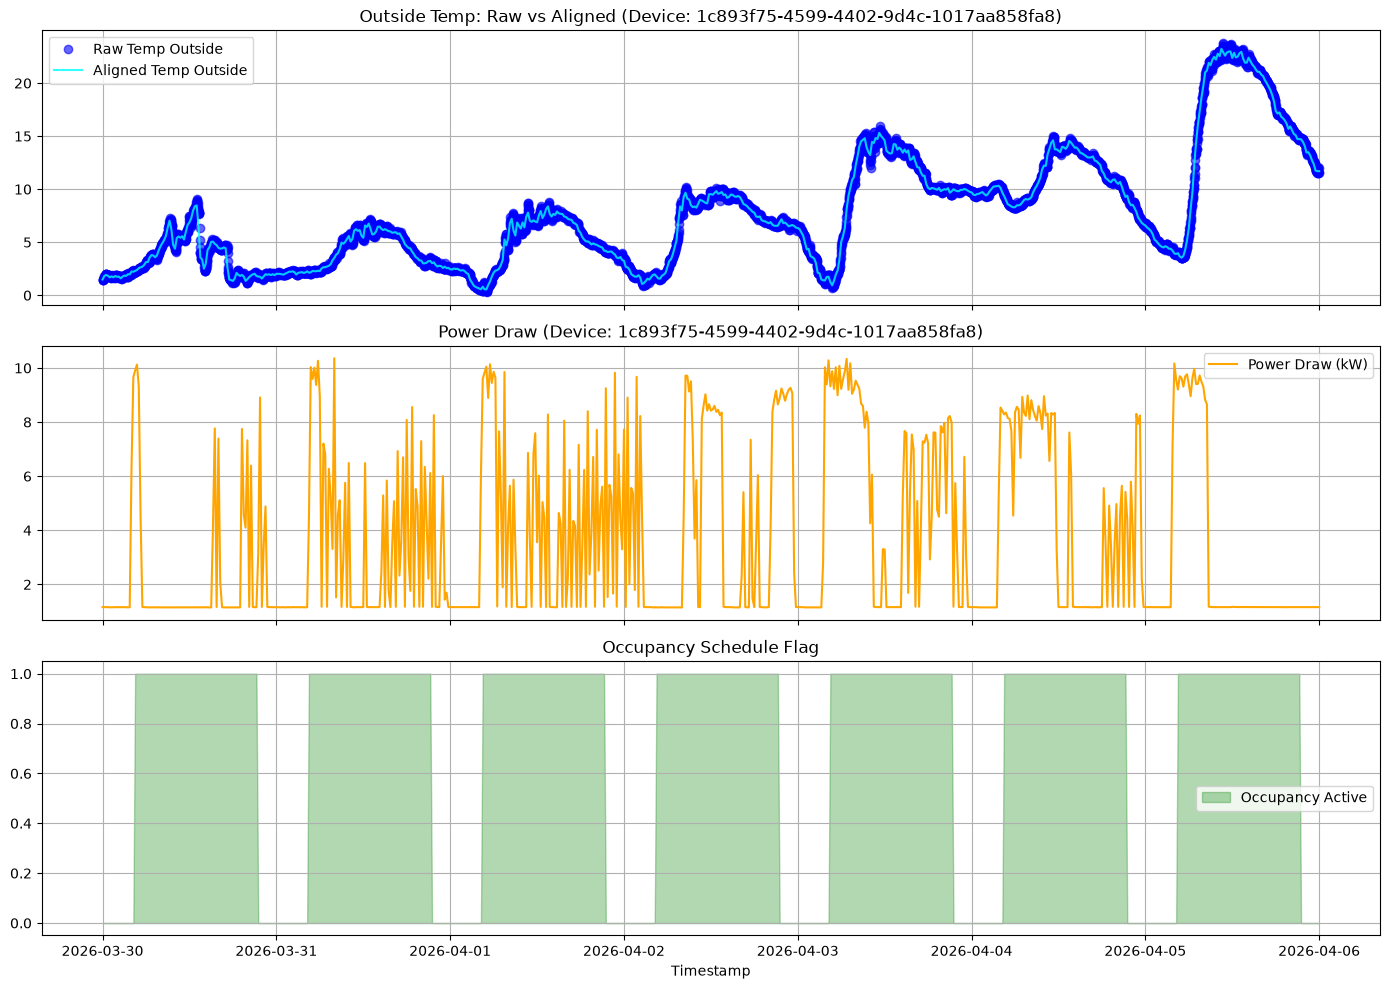

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

# Get the first device ID
device_id = aligned_heating["device_id"].dropna().unique()[0]
dev_raw_snap = snapshots_raw[snapshots_raw["device_id"] == device_id]
dev_aligned = aligned_heating[aligned_heating["device_id"] == device_id]

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Subplot 1: Temperature comparison
axes[0].plot(
    dev_raw_snap.index,
    dev_raw_snap["status_temperature_outside_in_celsius"],
    "o",
    color="blue",
    label="Raw Temp Outside",
    alpha=0.6,
)
axes[0].plot(
    dev_aligned.index,
    dev_aligned["outside_temperature"],
    "-",
    color="cyan",
    label="Aligned Temp Outside",
    alpha=0.8,
)
axes[0].set_title(f"Outside Temp: Raw vs Aligned (Device: {device_id})")
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Power Draw
axes[1].plot(
    dev_aligned.index,
    dev_aligned["power_draw_kw"],
    "-",
    color="orange",
    label="Power Draw (kW)",
)
axes[1].set_title(f"Power Draw (Device: {device_id})")
axes[1].legend()
axes[1].grid(True)

# Subplot 3: Occupancy Flag
axes[2].fill_between(
    dev_aligned.index,
    dev_aligned["occupancy_flag"],
    color="green",
    alpha=0.3,
    label="Occupancy Active",
)
axes[2].set_title("Occupancy Schedule Flag")
axes[2].legend()
axes[2].grid(True)

plt.xlabel("Timestamp")
plt.tight_layout()
plt.show()

# Section 7: Process Both Windows

We build and save the aligned datasets for both the heating and cooling windows. We save each using the shared utility helper `save_processed()` and output to the expected paths.

In [7]:
# Run for heating
heating_final, heating_report = build_aligned_dataset("heating")
save_processed(heating_final, "heating")
heating_path = PROJECT_ROOT / "backend/data/processed/processed_heating.csv"
heating_final.reset_index().to_csv(heating_path, index=False)

# Run for cooling
cooling_final, cooling_report = build_aligned_dataset("cooling")
save_processed(cooling_final, "cooling")
cooling_path = PROJECT_ROOT / "backend/data/processed/processed_cooling.csv"
cooling_final.reset_index().to_csv(cooling_path, index=False)

print("Heating final dataset shape:", heating_final.shape)
print("Cooling final dataset shape:", cooling_final.shape)
print("\nProcessed column list:")
print(list(heating_final.columns))

Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_low_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
/home/jovyan/heatsync/backend/notebooks/utils.py:129: UserWarning: Optional column 'status_high_pressure_highest_in_bar' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-30_to_2026-04-05/heat_pump_snapshots.csv'
  validate_columns(df, "snapshots", path_str)
Optional column 'status_fan_speed_in_rpm' is absent in file '/home/jovyan/heatsync/backend/data/heating_2026-03-

Heating final dataset shape: (2692, 61)
Cooling final dataset shape: (2692, 61)

Processed column list:
['status_is_enabled', 'status_target_temperature_in_celsius', 'status_temperature_in_celsius', 'status_humidity_in_percent', 'status_carbon_dioxide_in_ppm', 'status_voc_in_micrograms_per_cubic_meter', 'status_temperature_supply_in_celsius', 'status_temperature_return_in_celsius', 'status_temperature_outside_in_celsius', 'status_air_flow_supply_in_percent', 'status_air_flow_return_in_percent', 'status_is_heating_required', 'status_is_cooling_required', 'status_heat_threshold_in_celsius', 'status_cool_threshold_in_celsius', 'status_is_compressor_active', 'status_is_defrost_active', 'status_low_pressure_in_bar', 'status_high_pressure_in_bar', 'status_daily_shutdown_is_active', 'status_daily_shutdown_temperature_in_celsius', 'status_daily_shutdown_air_flow_supply_in_percent', 'status_daily_shutdown_air_flow_return_in_percent', 'status_is_status_active', 'status_is_alarm_active', 'status_

# Section 8: Summary

We print the coverage statistics for the processed heating and cooling datasets.

In [8]:
def print_summary_stats(df, name):
    metadata = df.attrs.get("interpolation_metadata", {})
    total_interpolations = sum(info.get("interpolated_count", 0) for info in metadata.values())
    print(f"=== {name} Dataset Summary ===")
    print(f"Total Row Count: {len(df)}")
    print(f"Date Range:      {df.index.min()} to {df.index.max()}")
    print(f"Column Count:    {len(df.columns)}")
    print(f"Total Interpolated Values: {total_interpolations}")
    print()


print_summary_stats(heating_final, "Heating")
print_summary_stats(cooling_final, "Cooling")

=== Heating Dataset Summary ===
Total Row Count: 2692
Date Range:      2026-03-30 00:00:00 to 2026-04-06 00:00:00
Column Count:    61
Total Interpolated Values: 0

=== Cooling Dataset Summary ===
Total Row Count: 2692
Date Range:      2026-05-25 00:00:00 to 2026-06-01 00:00:00
Column Count:    61
Total Interpolated Values: 0

